In [6]:
# Importing Data
import pandas as pd
import matplotlib.pyplot as plt
from pprint import pprint
import numpy as np
SKIP_ROWS = 11


df = pd.read_csv("mydata(6).csv")


df = df.dropna(how="all")
df.iloc[:, 0] = df.iloc[:, 0]*10
df.iloc[:, 1] = df.iloc[:, 1]*10

df["Y"] = df["Y"]*6
df["X"] = df["X"]*7

In [7]:
# Adding Columns
from pandas.api.indexers import FixedForwardWindowIndexer
DISTANCE_TO_CAMERA = 5050 # mm
BACKGROUND = 20
FULL_ROTATION = 300_000
N = len(df)
w = N // 4

def divergence(x):
    return 1000*(x.max() - x.min()) / DISTANCE_TO_CAMERA
    

# Wrap data
steps = np.linspace(0,FULL_ROTATION,len(df))
df["step"] = steps

dfb = pd.concat([df, df.head(w)], ignore_index=True)
indexer = FixedForwardWindowIndexer(window_size=w)
# Add standard devs
dfb["stdX"] = dfb.iloc[:, 0].rolling(window=indexer).std()
dfb["stdY"] = dfb.iloc[:, 1].rolling(window=indexer).std()
dfb["s"] = (dfb["stdX"]**2 + dfb["stdY"]**2)**0.5
dfb["divergence"] = dfb.iloc[:, 1].rolling(window=indexer).apply(divergence)


dfb.dropna(inplace=True)
dfb = dfb.iloc[:-1]

min_row = dfb["divergence"].idxmin()
dfb.iloc[min_row]

optimum_window = dfb.iloc[min_row:min_row+w]


# Results


s: 273.00
estimated_div_x: 127.95 mrad
estimated_div_y: 63.98 mrad
estimated_div: 107.951683


232075 CW
67925 CW




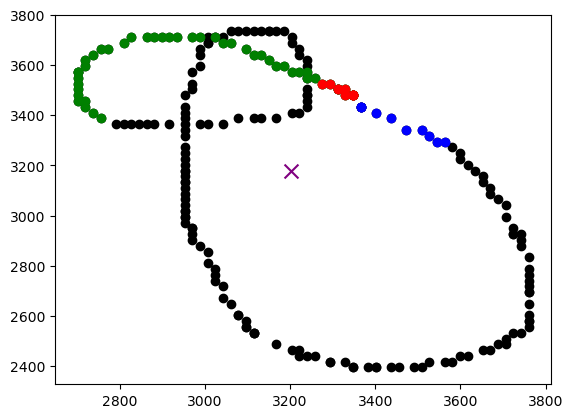

In [8]:
#Plotting
NODE_LENGTH = 10
plt.scatter(dfb.iloc[:, 0],dfb.iloc[:, 1], color="k")
plt.scatter(optimum_window.iloc[:, 0],optimum_window.iloc[:, 1], color="green")
plt.scatter(dfb.iloc[:, 0][:NODE_LENGTH],dfb.iloc[:, 1][:NODE_LENGTH], color="blue")
plt.scatter(dfb.iloc[:, 0][-NODE_LENGTH:], dfb.iloc[:, 1][-NODE_LENGTH:], color="red")
plt.scatter(dfb.iloc[:, 0].mean(), dfb.iloc[:, 1].mean(), color="purple", marker="x", s=100)

optimal_step = optimum_window.iloc[0]["step"]
optimal_s = optimum_window.iloc[0]["s"]
estimated_div_x = divergence(  optimum_window.iloc[:, 0]   )
estimated_div_y = divergence(  optimum_window.iloc[:, 1]   )

print(F"""
s: {optimal_s:.2f}
estimated_div_x: {estimated_div_x:.2f} mrad
estimated_div_y: {estimated_div_y:.2f} mrad
estimated_div: { (((estimated_div_x+estimated_div_x)/2) - BACKGROUND) :2f}
""")

print(F"""
{optimal_step:.0f} CW
{(FULL_ROTATION - optimal_step):.0f} CW

""")

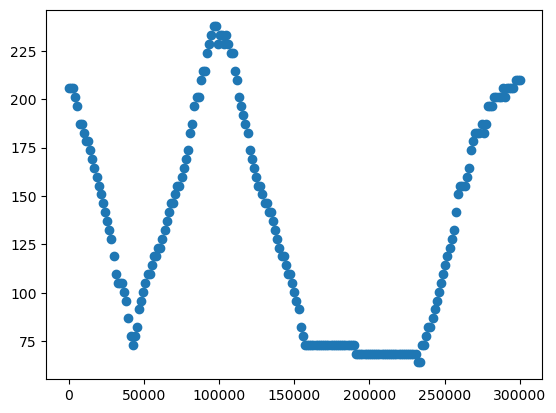

In [26]:
plt.scatter(dfb["step"], dfb["divergence"])

In [13]:
import numpy as np
import pandas as pd
from scipy.fft import fft

df = pd.read_csv("mydata(6).csv")
df["Y"] = df["Y"]*6
df["X"] = df["X"]*7


z = df["X"].to_numpy() + 1j * df["Y"].to_numpy()

N = len(z)

# Complex coefss in 1 -1 pairs
c = fft(z) / N


In [22]:
amplitudes = np.array([
    np.sqrt(abs(c[k])**2 + abs(c[-k])**2)
    for k in range(1, N//2)
])

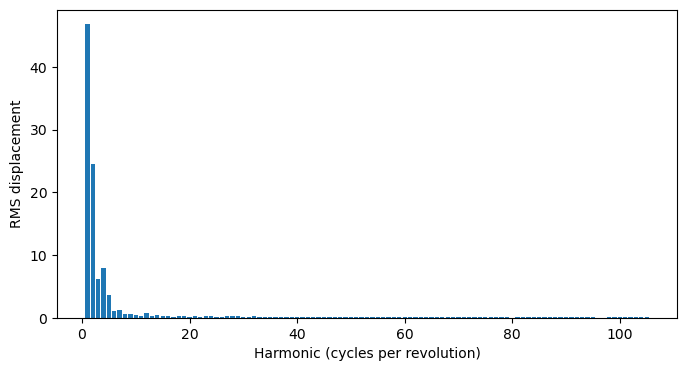

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.bar(np.arange(1, len(amplitudes) + 1), amplitudes)
plt.xlabel("Harmonic (cycles per revolution)")
plt.ylabel("Portion")
plt.show()


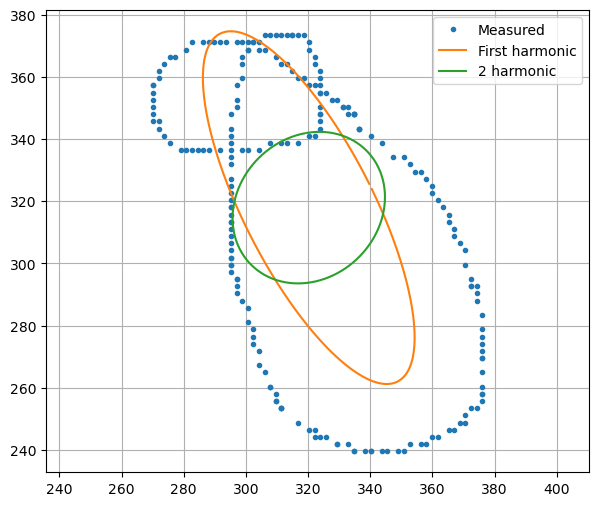

In [25]:

theta = 2 * np.pi * np.arange(N) / N

z1 = (
    c[0]
    + c[1] * np.exp(1j * theta)
    + c[-1] * np.exp(-1j * theta)
)
z2 = (
    c[0]
    + c[2] * np.exp(1j * theta)
    + c[-2] * np.exp(-1j * theta)
)
plt.figure(figsize=(7, 6))

plt.plot(z.real, z.imag, ".", label="Measured")
plt.plot(z1.real, z1.imag, label="First harmonic")
plt.plot(z2.real, z2.imag, label="2 harmonic")

plt.axis("equal")
plt.legend()
plt.grid()
plt.show()
